# Ekstraksi Fitur Citra Digital: Momen Warna RGB, Konversi Grayscale 8-Bit, Tekstur (GLCM Haralick), dan Pemodelan Klasifikasi 
## Analisis Komparasi Multi-Model (SVM RBF, Random Forest, Logistic Regression, KNN, Naive Bayes, Decision Tree)

**Mata Kuliah:** Proyek Sains Data (PSD)  
**Topik Praktikum:** Ekstraksi 14 Fitur Citra Digital & Pemodelan Klasifikasi Kerapian Ruangan  
**Dataset:** 200 Citra Digital Ruangan (100 Berantakan & 100 Rapi)

---
### Daftar Isi
1. **Business Understanding**
   - 1.1 Latar Belakang & Urgensi Deteksi Kerapian Ruangan
   - 1.2 Rumusan Masalah
   - 1.3 Tujuan Penelitian & Eksperimen
   - 1.4 Manfaat Akademik & Terapan
   - 1.5 Alur Kerja Sistem (End-to-End Pipeline)
2. **Data Understanding**
   - 2.1 Deskripsi Dataset (Arsip `berantakan.zip` & `rapi.zip`)
   - 2.2 Karakteristik & Resolusi Spasial Citra
3. **Data Preparation**
   - 3.1 Persiapan Lingkungan & Konfigurasi Library
   - 3.2 Pemeriksaan Isi Arsip ZIP & Sampel Citra
   - 3.3 Dekomposisi Kanal Warna RGB & Konversi Grayscale 8-Bit (ITU-R BT.601)
4. **Deskripsi Fitur dan Rumus Matematis**
   - 4.1 Momen Warna Kanal RGB (9 Fitur: Mean, Std, Skewness)
   - 4.2 Fitur Tekstur Spasial GLCM Haralick (5 Fitur: Energy, Entropy, Contrast, Correlation, Homogeneity)
   - 4.3 Hipotesis Fitur Visual
   - 4.4 Ringkasan Vektor Fitur (14 Fitur Inti + 1 Label Kategori)
5. **Ekstraksi Fitur Citra Digital**
   - 5.1 Implementasi Algoritma Ekstraksi 14 Fitur
   - 5.2 Pemrosesan Batch Dataset & Ekspor ke Berkas CSV
6. **Eksplorasi Data (EDA)**
   - 6.1 Statistik Deskriptif Per Kategori Ruangan
   - 6.2 Perbandingan Rata-rata Fitur Antar Kategori
   - 6.3 Visualisasi Sebaran Fitur Kunci (Histogram & Boxplot)
   - 6.4 Matriks Korelasi Pearson Antar 14 Fitur
7. **Pemodelan Klasifikasi Seperti Audio Kemarin**
   - 7.1 Stratified Train-Test Split (80:20) & Standarisasi Z-Score (`StandardScaler`)
   - 7.2 Benchmark 6 Model Klasifikasi & 5-Fold Stratified Cross-Validation
8. **Evaluasi Model Komprehensif**
   - 8.1 Tabel Benchmark Kinerja Model Klasifikasi
   - 8.2 Visualisasi Matriks Akurasi / Matriks Konfusi (Confusion Matrix)
   - 8.3 Kurva ROC (Receiver Operating Characteristic) & Skor AUC
   - 8.4 Analisis Tingkat Kepentingan Fitur (Feature Importance Random Forest)
   - 8.5 Serialisasi Model Terbaik & Scaler (`.pkl`) serta Metadata JSON
9. **Kesimpulan & Rekomendasi**
   - 9.1 Kesimpulan Analisis
   - 9.2 Rekomendasi Pengembangan


---
# 1. Business Understanding

## 1.1 Latar Belakang
Kerapian dan keteraturan ruangan merupakan indikator krusial dalam menciptakan kenyamanan hunian, efisiensi kerja, dan kepatuhan standar kebersihan pada industri perhotelan (*smart hospitality*), perkantoran, dan fasilitas umum cerdas (*smart facility management*). Secara tradisional, penilaian kondisi ruangan dilakukan melalui inspeksi visual langsung oleh petugas, yang memakan waktu, berbiaya tinggi, dan sangat rentan terhadap subjektivitas antar-individu penilai.

Pemanfaatan **Pengolahan Citra Digital (Digital Image Processing)** yang dipadukan dengan **Machine Learning** memungkinkan proses inspeksi ruangan dilakukan secara otomatis, objektif, dan terstandarisasi. Citra foto ruangan diekstraksi ke dalam vektor representasi kuantitatif berdimensi 14 fitur inti, mencakup distribusi warna (momen warna RGB) dan karakteristik tekstur spasial (GLCM Haralick). Ruangan berantakan memiliki ciri khas berupa variasi intensitas warna yang tinggi (standar deviasi tinggi), kontras spasial tinggi, dan keacakan tekstur yang besar (entropi tinggi). Sebaliknya, ruangan yang rapi didominasi oleh permukaan bidang datar yang teratur, ditandai dengan keseragaman tekstur tinggi (energi tinggi) dan homogenitas transisi keabuan yang tinggi.

## 1.2 Rumusan Masalah
1. Bagaimana mengekstrak momen warna orde 1 hingga orde 3 (mean, standard deviation, skewness) dari kanal warna Red, Green, dan Blue pada dataset citra ruangan?
2. Bagaimana mengonversi citra RGB ke citra grayscale diskrit 8-bit serta membentuk matriks ko-okurensi spasial (GLCM) untuk mengekstrak 5 fitur tekstur Haralick (energi, entropi, kontras, korelasi, dan homogenitas)?
3. Bagaimana menyusun seluruh hasil ekstraksi ke dalam berkas CSV tabular (14 fitur numerik + 1 kolom label)?
4. Bagaimana performa berbagai algoritma klasifikasi (SVM RBF, Random Forest, Logistic Regression, KNN, Naive Bayes, Decision Tree) jika diuji dengan alur yang identik dengan praktikum audio kemarin (*Stratified Train-Test Split 80:20*, *StandardScaler*, dan *5-Fold Stratified Cross-Validation*)?
5. Fitur visual manakah yang memiliki kontribusi terbesar (*feature importance*) dalam memisahkan kondisi ruangan berantakan vs rapi?

## 1.3 Tujuan Penelitian
1. Mengembangkan pipeline ekstraksi 14 fitur citra digital secara otomatis dari berkas arsip `berantakan.zip` dan `rapi.zip`.
2. Mengekspor dataset fitur tabular berstandar CSV untuk analisis sains data terstruktur.
3. Mengimplementasikan protokol klasifikasi multi-model (*benchmarking*) sesuai alur modul klasifikasi audio.
4. Mengevaluasi keandalan model melalui metrik komprehensif: akurasi pengujian, 5-fold cross-validation, matriks konfusi, precision, recall, F1-score, dan ROC-AUC.
5. Menentukan fitur visual paling signifikan melalui analisis *feature importance* model Random Forest.

## 1.4 Manfaat
| Sektor | Manfaat Nyata |
| :--- | :--- |
| **Akademik** | Penguasaan terapan ekstraksi fitur citra digital (warna & tekstur spasial GLCM) dan machine learning |
| **Smart Hospitality** | Otomasi verifikasi kesiapan dan kerapian kamar hotel sebelum diserahkan kepada tamu |
| **Smart Office / Facility** | Pemantauan kebersihan dan keteraturan ruang kerja secara terjadwal melalui kamera IoT |
| **Quality Assurance** | Standarisasi penilaian kebersihan fasilitas publik tanpa bias subjektif petugas |

## 1.5 Alur Kerja Sistem (End-to-End Pipeline)
```
[Arsip Citra Mentah: data/raw/berantakan.zip & rapi.zip (Total 200 Citra)]
                               │
                               ▼
        [Normalisasi Spasial: Resize Seragam 256 x 256 Piksel]
                               │
       ┌───────────────────────┴───────────────────────┐
       ▼                                               ▼
[Dekomposisi Kanal RGB]               [Konversi Grayscale 8-Bit (BT.601)]
       │                                               │
       ▼                                               ▼
[9 Momen Warna (Orde 1-3)]            [Pembentukan Matriks GLCM d=1, 4 Arah]
- Mean (R, G, B)                                       │
- Standard Deviation (R, G, B)                         ▼
- Skewness (R, G, B)                  [5 Fitur Tekstur Spasial Haralick]
                                      - Energy (Keseragaman Kuadratik)
                                      - Entropy (Derajat Keacakan)
                                      - Contrast (Variasi Lokal)
                                      - Correlation (Ketergantungan Linier)
                                      - Homogeneity (Kelancaran Transisi)
       │                                               │
       └───────────────────────┬───────────────────────┘
                               ▼
     [Dataset Terstruktur: 14 Fitur + 1 Label Biner (CSV)]
                               │
                               ▼
    [Eksplorasi Data (EDA): Statistik, Histogram, Boxplot, Heatmap Korelasi]
                               │
                               ▼
       [Protokol Klasifikasi Seperti Audio Kemarin]
       ├── Stratified Train-Test Split (80% Train : 20% Test)
       ├── Standarisasi Fitur Z-Score (StandardScaler)
       ├── 5-Fold Stratified Cross-Validation
       └── Pelatihan 6 Model: SVM (RBF), Random Forest, Logistic Regression, KNN, Naive Bayes, Decision Tree
                               │
                               ▼
       [Evaluasi Komprehensif & Visualisasi]
       ├── Tabel Komparasi Benchmark Metrik
       ├── Matriks Akurasi (Confusion Matrix) untuk Seluruh Model
       ├── Kurva ROC & Skor Area Under Curve (AUC)
       └── Analisis Tingkat Kepentingan Fitur (Feature Importance)
                               │
                               ▼
     [Serialisasi Model Terbaik (.pkl) + Scaler + Metadata JSON]
```


---
# 2. Data Understanding

## 2.1 Karakteristik Dataset
Dataset yang digunakan memuat **200 citra digital ruangan nyata** yang terbagi rata ke dalam 2 kelas target:

| ID | Kategori Ruangan | Berkas Sumber | Jumlah Sampel | Target Numerik | Interpretasi Visual |
| :---: | :--- | :--- | :---: | :---: | :--- |
| **0** | **Rapi** | `data/raw/rapi.zip` | 100 citra | `0` | Perabot tertata simetris, lantai/meja bersih, pola bidang datar dominan |
| **1** | **Berantakan** | `data/raw/berantakan.zip` | 100 citra | `1` | Barang berserakan, variasi warna tidak teratur, kontras tinggi |
| **Total** | **2 Kategori** | **2 Berkas ZIP** | **200 citra** | **Biner** | **Dataset berimbang (balanced 50:50)** |

## 2.2 Properti Format & Resolusi Citra
- **Format Berkas Asli:** JPEG, JPG, PNG, dan HEIC.
- **Ruang Warna:** RGB 24-bit (3 kanal independen: Red, Green, Blue dengan intensitas diskrit 0–255).
- **Normalisasi Dimensi:** Seluruh citra di-resize menjadi dimensi seragam $256 \times 256$ piksel untuk menjamin invariansi statistik spasial dan efisiensi waktu komputasi GLCM.


---
# 3. Data Preparation

## 3.1 Persiapan Lingkungan & Konfigurasi Library


In [1]:
import os
import io
import json
import zipfile
import joblib
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import scipy.stats as stats
from PIL import Image

import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

from skimage.feature import graycomatrix, graycoprops
from skimage.color import rgb2gray
from skimage.util import img_as_ubyte

# Scikit-Learn Machine Learning Modules
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    roc_curve, auc
)

# Dukungan membaca berkas citra format HEIC/HEIF
try:
    from pillow_heif import register_heif_opener
    register_heif_opener()
    print("✅ Modul pillow-heif aktif: format HEIC/HEIF didukung penuh.")
except ImportError:
    print("⚠ Modul pillow-heif belum terpasang. Berkas .heic akan dilewati jika ada.")

# Konfigurasi Path dan Parameter Proyek
SEED = 42
IMG_SIZE = (256, 256)
VALID_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.tiff', '.heic'}

ZIP_BERANTAKAN = os.path.join('data', 'raw', 'berantakan.zip')
ZIP_RAPI       = os.path.join('data', 'raw', 'rapi.zip')
OUTPUT_CSV     = os.path.join('data', 'hasil_ekstraksi_fitur_citra.csv')
BACKUP_CSV     = os.path.join('data', 'fitur_gambar.csv')
MODELS_DIR     = os.path.join('data', 'models')

os.makedirs('data', exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

print(f"Path Arsip Berantakan : {ZIP_BERANTAKAN} (Ada: {os.path.exists(ZIP_BERANTAKAN)})")
print(f"Path Arsip Rapi       : {ZIP_RAPI} (Ada: {os.path.exists(ZIP_RAPI)})")


C:\Users\LENOVO\.matplotlib is not a writable directory


Matplotlib created a temporary cache directory at C:\Users\LENOVO\AppData\Local\Temp\matplotlib-vy87sykt because there was an issue with the default path (C:\Users\LENOVO\.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


✅ Modul pillow-heif aktif: format HEIC/HEIF didukung penuh.
Path Arsip Berantakan : data\raw\berantakan.zip (Ada: True)
Path Arsip Rapi       : data\raw\rapi.zip (Ada: True)


## 3.2 Pemeriksaan Isi Arsip ZIP & Sampel Citra


In [2]:
def list_images_in_zip(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zf:
        return [
            f for f in zf.namelist()
            if not f.endswith('/') and not f.startswith('__MACOSX')
            and os.path.splitext(f)[1].lower() in VALID_EXT
        ]

files_berantakan = list_images_in_zip(ZIP_BERANTAKAN)
files_rapi       = list_images_in_zip(ZIP_RAPI)

print(f"Total citra Berantakan : {len(files_berantakan)} berkas")
print(f"Total citra Rapi       : {len(files_rapi)} berkas")
print(f"Total Keseluruhan      : {len(files_berantakan) + len(files_rapi)} berkas citra")


Total citra Berantakan : 100 berkas
Total citra Rapi       : 100 berkas
Total Keseluruhan      : 200 berkas citra


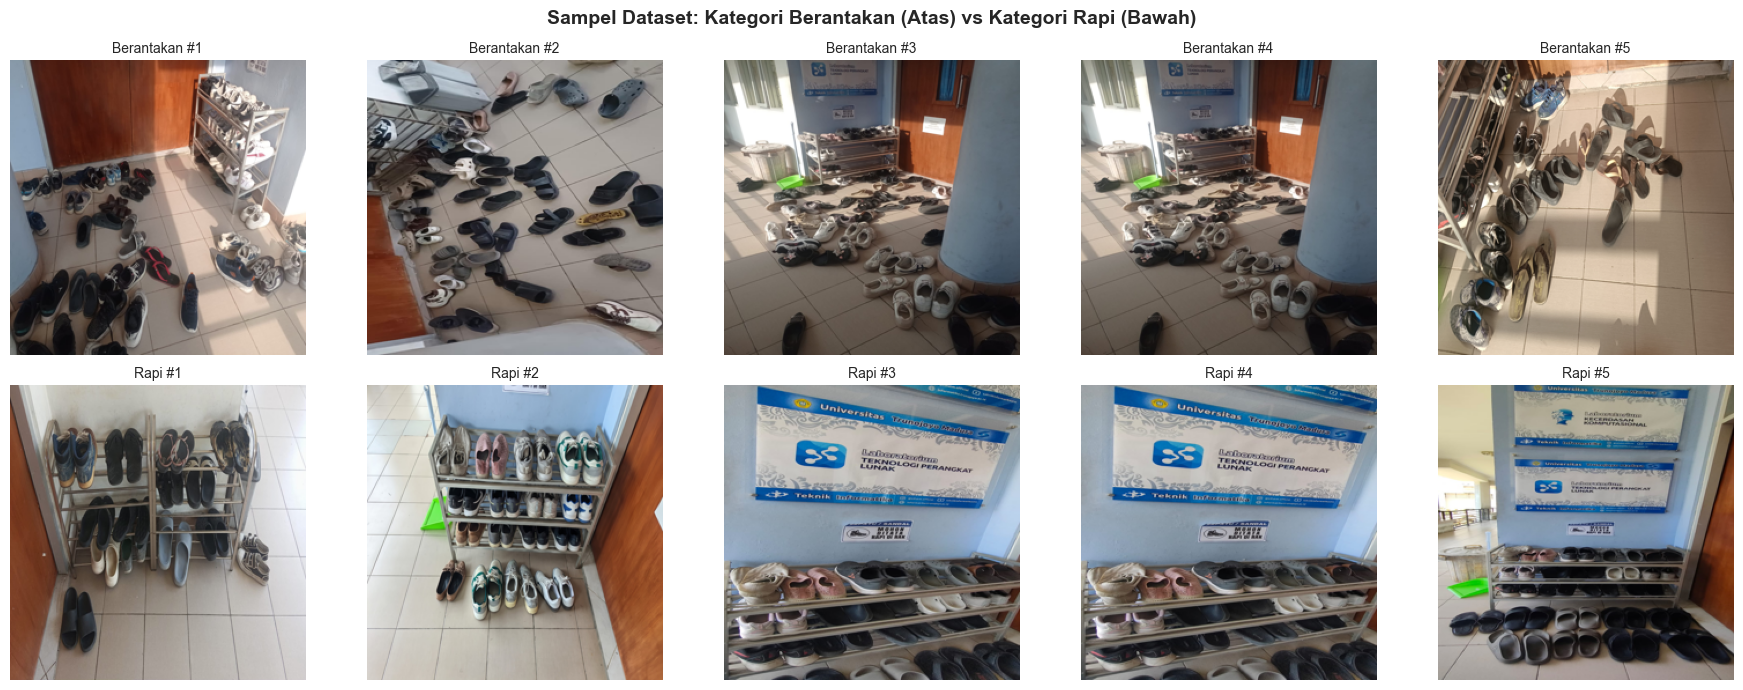

In [3]:
def load_image_from_zip(zf, filename):
    with zf.open(filename) as f:
        img = Image.open(io.BytesIO(f.read()))
        img = img.convert('RGB')
        img = img.resize(IMG_SIZE)
    return img

# Menampilkan 5 sampel gambar dari masing-masing kategori
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
fig.suptitle('Sampel Dataset: Kategori Berantakan (Atas) vs Kategori Rapi (Bawah)', fontsize=14, fontweight='bold')

for col in range(5):
    with zipfile.ZipFile(ZIP_BERANTAKAN, 'r') as zf:
        img_b = load_image_from_zip(zf, files_berantakan[col])
    axes[0, col].imshow(img_b)
    axes[0, col].set_title(f"Berantakan #{col+1}", fontsize=10)
    axes[0, col].axis('off')

    with zipfile.ZipFile(ZIP_RAPI, 'r') as zf:
        img_r = load_image_from_zip(zf, files_rapi[col])
    axes[1, col].imshow(img_r)
    axes[1, col].set_title(f"Rapi #{col+1}", fontsize=10)
    axes[1, col].axis('off')

plt.tight_layout()
plt.show()


## 3.3 Dekomposisi Kanal Warna RGB & Konversi Grayscale 8-Bit (ITU-R BT.601)


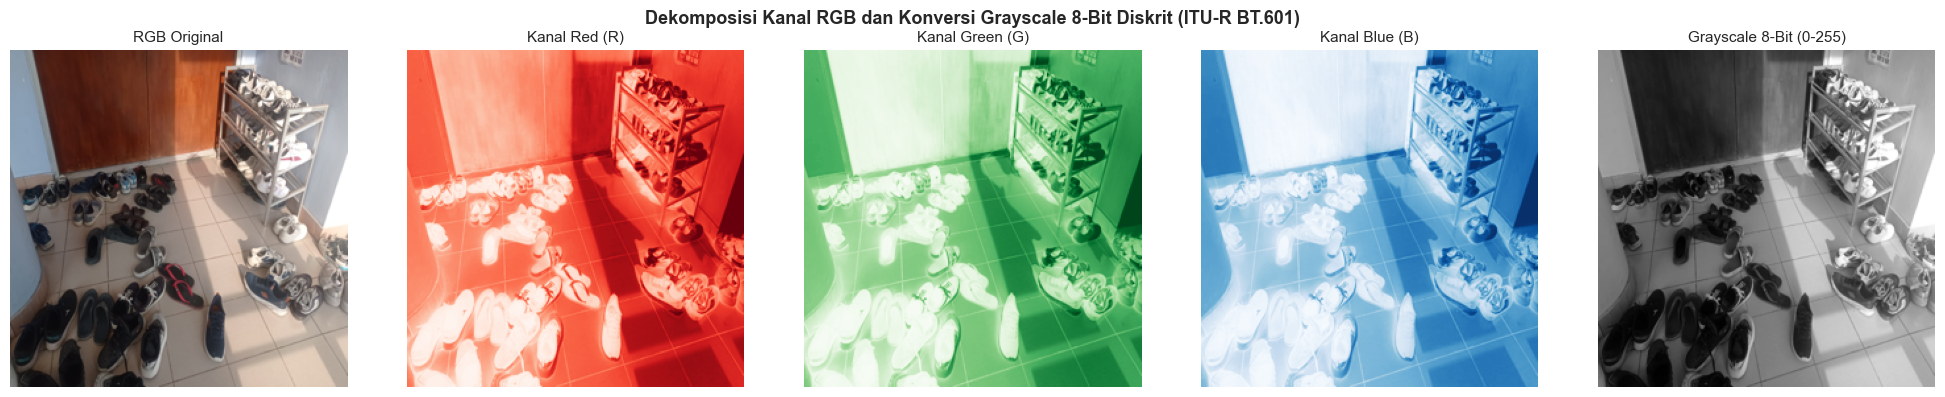

Dimensi Array RGB       : (256, 256, 3) (Tinggi, Lebar, Kanal)
Dimensi Array Grayscale : (256, 256) (Rentang nilai: 7 s.d. 255)


In [4]:
with zipfile.ZipFile(ZIP_BERANTAKAN, 'r') as zf:
    sample_img = load_image_from_zip(zf, files_berantakan[0])

sample_arr = np.array(sample_img)
sample_gray = rgb2gray(sample_arr)
sample_gray_8bit = img_as_ubyte(sample_gray)

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
fig.suptitle('Dekomposisi Kanal RGB dan Konversi Grayscale 8-Bit Diskrit (ITU-R BT.601)', fontsize=13, fontweight='bold')

axes[0].imshow(sample_arr)
axes[0].set_title('RGB Original', fontsize=11)
axes[0].axis('off')

axes[1].imshow(sample_arr[:, :, 0], cmap='Reds')
axes[1].set_title('Kanal Red (R)', fontsize=11)
axes[1].axis('off')

axes[2].imshow(sample_arr[:, :, 1], cmap='Greens')
axes[2].set_title('Kanal Green (G)', fontsize=11)
axes[2].axis('off')

axes[3].imshow(sample_arr[:, :, 2], cmap='Blues')
axes[3].set_title('Kanal Blue (B)', fontsize=11)
axes[3].axis('off')

axes[4].imshow(sample_gray_8bit, cmap='gray')
axes[4].set_title('Grayscale 8-Bit (0-255)', fontsize=11)
axes[4].axis('off')

plt.tight_layout()
plt.show()

print(f"Dimensi Array RGB       : {sample_arr.shape} (Tinggi, Lebar, Kanal)")
print(f"Dimensi Array Grayscale : {sample_gray_8bit.shape} (Rentang nilai: {sample_gray_8bit.min()} s.d. {sample_gray_8bit.max()})")


---
# 4. Deskripsi Fitur dan Rumus Matematis

Sesuai dengan instruksi perkuliahan Penambangan Sains Data (PSD) dan materi dosen, vektor input berdimensi **14 fitur inti numerik + 1 kolom label target**:

## 4.1 Momen Warna Kanal RGB (9 Fitur)
Dihitung secara terpisah pada setiap kanal $C \in \{R, G, B\}$:
1. **Momen Pertama - Mean (Rata-rata Intensitas):**
   $$\mu_C = \frac{1}{N} \sum_{i=1}^{N} x_{C, i}$$
2. **Momen Kedua - Standard Deviation (Standar Deviasi / Kontras Warna):**
   $$\sigma_C = \sqrt{\frac{1}{N} \sum_{i=1}^{N} (x_{C, i} - \mu_C)^2}$$
3. **Momen Ketiga - Skewness (Kemiringan Distribusi Intensitas):**
   $$\gamma_C = \frac{1}{N} \sum_{i=1}^{N} \left(\frac{x_{C, i} - \mu_C}{\sigma_C}\right)^3$$

Tersusun atas 9 fitur warna: `mean_r`, `std_r`, `skew_r`, `mean_g`, `std_g`, `skew_g`, `mean_b`, `std_b`, `skew_b`.

## 4.2 Fitur Tekstur Spasial GLCM Haralick (5 Fitur)
Citra RGB dikonversi ke grayscale 8-bit, lalu dibentuk matriks ko-okurensi spasial ternormalisasi $P(i, j)$ dengan jarak piksel $d=1$ pada 4 arah orientasi ($0^\circ, 45^\circ, 90^\circ, 135^\circ$) yang dirata-ratakan:
1. **Energy / Angular Second Moment (ASM):**
   $$\text{Energy} = \sum_{i} \sum_{j} P(i, j)^2$$
   *Mengukur keseragaman susunan intensitas kuadratik. Bernilai tinggi pada tekstur homogen dan berulang.*
2. **Entropy (Derajat Keacakan Tekstur):**
   $$\text{Entropy} = -\sum_{i} \sum_{j} P(i, j) \log_2(P(i, j) + \epsilon)$$
   *Mengukur ketidakteraturan susunan spasial piksel. Bernilai tinggi pada tekstur acak/kompleks.*
3. **Contrast (Variasi Intensitas Lokal):**
   $$\text{Contrast} = \sum_{i} \sum_{j} (i - j)^2 P(i, j)$$
   *Mengukur perbedaan kontras lokal antar pasangan piksel tetangga.*
4. **Correlation (Ketergantungan Linier Nilai Keabuan Spasial):**
   $$\text{Correlation} = \sum_{i} \sum_{j} \frac{(i - \mu_i)(j - \mu_j) P(i, j)}{\sigma_i \sigma_j}$$
   *Mengukur derajat korelasi linier intensitas piksel dengan tetangganya.*
5. **Homogeneity / Inverse Difference Moment (IDM):**
   $$\text{Homogeneity} = \sum_{i} \sum_{j} \frac{P(i, j)}{1 + (i - j)^2}$$
   *Mengukur kelembutan transisi keabuan. Bernilai tinggi jika selisih $(i - j)$ mendekati nol (diagonal).*

Tersusun atas 5 fitur tekstur: `glcm_energy`, `glcm_entropy`, `glcm_contrast`, `glcm_correlation`, `glcm_homogeneity`.

## 4.3 Hipotesis Fitur Visual
| Fitur Visual | Ruangan Berantakan | Ruangan Rapi |
| :--- | :---: | :---: |
| **Standar Deviasi Warna (std_r, std_g, std_b)** | **Tinggi** (variasi objek/warna sangat beragam) | **Rendah** (warna lebih seragam/monokromatik) |
| **GLCM Energy** | **Rendah** (distribusi probabilitas menyebar merata) | **Tinggi** (probabilitas terkonsentrasi pada pola seragam) |
| **GLCM Entropy** | **Tinggi** (kompleksitas susunan spasial tinggi) | **Rendah** (pola ruang lebih terstruktur dan sederhana) |
| **GLCM Contrast** | **Tinggi** (perbedaan tajam batas antar-objek berserakan) | **Rendah** (permukaan bidang meja/lantai rata) |
| **GLCM Homogeneity** | **Rendah** (banyak transisi intensitas lokal yang tajam) | **Tinggi** (gradasi dan transisi intensitas sangat halus) |

## 4.4 Ringkasan Vektor Fitur
$$\mathbf{x} = [\mu_r, \sigma_r, \gamma_r, \mu_g, \sigma_g, \gamma_g, \mu_b, \sigma_b, \gamma_b, \text{Energy}, \text{Entropy}, \text{Contrast}, \text{Correlation}, \text{Homogeneity}]^T \in \mathbb{R}^{14}$$
Target klasifikasi biner: $y \in \{0, 1\}$ di mana $0 = \text{Rapi}$ dan $1 = \text{Berantakan}$.


---
# 5. Ekstraksi Fitur Citra Digital

## 5.1 Implementasi Algoritma Ekstraksi 14 Fitur


In [5]:
def extract_14_features(img_pil):
    """
    Mengekstrak 14 fitur inti dari citra PIL:
    - 9 Fitur Momen Warna (Mean, Std, Skewness pada kanal R, G, B)
    - 5 Fitur Tekstur Spasial GLCM (Energy, Entropy, Contrast, Correlation, Homogeneity)
    """
    arr = np.array(img_pil)
    feats = {}

    # 1. Ekstraksi 9 Fitur Momen Warna RGB
    channel_names = ['r', 'g', 'b']
    for idx, ch in enumerate(channel_names):
        vals = arr[:, :, idx].flatten().astype(np.float64)
        feats[f'mean_{ch}'] = float(np.mean(vals))
        feats[f'std_{ch}']  = float(np.std(vals))
        feats[f'skew_{ch}'] = float(stats.skew(vals))

    # 2. Konversi Grayscale 8-bit & Ekstraksi 5 Fitur GLCM Haralick
    gray = rgb2gray(arr)
    gray_ubyte = img_as_ubyte(gray)

    distances = [1]
    angles = [0, np.pi/4, np.pi/2, 3*np.pi/4]
    glcm = graycomatrix(gray_ubyte, distances=distances, angles=angles, levels=256, symmetric=True, normed=True)

    feats['glcm_energy']      = float(graycoprops(glcm, 'energy').mean())
    feats['glcm_contrast']    = float(graycoprops(glcm, 'contrast').mean())
    feats['glcm_correlation'] = float(graycoprops(glcm, 'correlation').mean())
    feats['glcm_homogeneity'] = float(graycoprops(glcm, 'homogeneity').mean())

    # Entropi Shannon dari distribusi ko-okurensi: -sum(P * log2(P))
    entropies = []
    for a in range(glcm.shape[3]):
        p_matrix = glcm[:, :, 0, a]
        mask = p_matrix > 0
        h = -np.sum(p_matrix[mask] * np.log2(p_matrix[mask]))
        entropies.append(h)
    feats['glcm_entropy'] = float(np.mean(entropies))

    return feats

print("✅ Fungsi extract_14_features berhasil dikompilasi.")


✅ Fungsi extract_14_features berhasil dikompilasi.


## 5.2 Pemrosesan Batch Dataset & Ekspor ke Berkas CSV


In [6]:
def load_or_process_dataset():
    # Jika CSV hasil ekstraksi sudah tersedia, muat langsung untuk efisiensi
    if os.path.exists(OUTPUT_CSV):
        print(f"📥 Memuat dataset fitur yang sudah diekstrak dari: {OUTPUT_CSV}")
        return pd.read_csv(OUTPUT_CSV)
    
    print("Mengekstrak 14 fitur dari 200 citra pada berkas ZIP...")
    records = []
    
    # 1. Kategori Berantakan (label = 1)
    with zipfile.ZipFile(ZIP_BERANTAKAN, 'r') as zf:
        fnames = [f for f in zf.namelist() if not f.endswith('/') and not f.startswith('__MACOSX') and os.path.splitext(f)[1].lower() in VALID_EXT]
        for fn in fnames:
            try:
                img = load_image_from_zip(zf, fn)
                f_dict = extract_14_features(img)
                f_dict['filename'] = os.path.basename(fn)
                f_dict['category'] = 'Berantakan'
                f_dict['label'] = 1
                records.append(f_dict)
            except Exception as e:
                print(f"Gagal memproses {fn}: {e}")

    # 2. Kategori Rapi (label = 0)
    with zipfile.ZipFile(ZIP_RAPI, 'r') as zf:
        fnames = [f for f in zf.namelist() if not f.endswith('/') and not f.startswith('__MACOSX') and os.path.splitext(f)[1].lower() in VALID_EXT]
        for fn in fnames:
            try:
                img = load_image_from_zip(zf, fn)
                f_dict = extract_14_features(img)
                f_dict['filename'] = os.path.basename(fn)
                f_dict['category'] = 'Rapi'
                f_dict['label'] = 0
                records.append(f_dict)
            except Exception as e:
                print(f"Gagal memproses {fn}: {e}")

    df_res = pd.DataFrame(records)
    feature_columns = [
        'mean_r', 'std_r', 'skew_r',
        'mean_g', 'std_g', 'skew_g',
        'mean_b', 'std_b', 'skew_b',
        'glcm_energy', 'glcm_entropy', 'glcm_contrast', 'glcm_correlation', 'glcm_homogeneity'
    ]
    ordered_cols = ['filename', 'category', 'label'] + feature_columns
    df_res = df_res[ordered_cols]
    
    df_res.to_csv(OUTPUT_CSV, index=False)
    df_res.to_csv(BACKUP_CSV, index=False)
    print(f"✅ Ekstraksi selesai. Data disimpan ke {OUTPUT_CSV} dan {BACKUP_CSV}")
    return df_res

df = load_or_process_dataset()

feature_cols = [
    'mean_r', 'std_r', 'skew_r',
    'mean_g', 'std_g', 'skew_g',
    'mean_b', 'std_b', 'skew_b',
    'glcm_energy', 'glcm_entropy', 'glcm_contrast', 'glcm_correlation', 'glcm_homogeneity'
]

print(f"Dimensi Dataframe : {df.shape[0]} baris × {df.shape[1]} kolom")
print(f"Sebaran Label     :\n{df['category'].value_counts()}")
display(df.head(10))


📥 Memuat dataset fitur yang sudah diekstrak dari: data\hasil_ekstraksi_fitur_citra.csv
Dimensi Dataframe : 200 baris × 17 kolom
Sebaran Label     :
category
Berantakan    100
Rapi          100
Name: count, dtype: int64


,mean_r,std_r,skew_r,mean_g,std_g,skew_g,mean_b,std_b,skew_b,glcm_energy,glcm_contrast,glcm_correlation,glcm_homogeneity,glcm_entropy,filename,category,label
0,128.014771,61.740802,-0.007063,110.681778,62.920356,0.121530,104.119720,63.715716,0.152904,0.023325,280.221092,0.963331,0.320627,12.428008,24-034 Berantakan 1.jpg,Berantakan,1
1,119.143738,48.201036,-0.522118,111.833832,50.142506,-0.231985,108.915237,51.158462,-0.114223,0.031704,343.416046,0.929634,0.328328,12.163363,24-026 Berantakan 3.jpeg,Berantakan,1
2,108.544189,55.056128,0.811059,101.395828,53.712114,0.824118,96.532623,52.813747,0.794264,0.036335,291.910673,0.948574,0.352170,11.903676,24-003 Berantakan 2.jpg,Berantakan,1
3,108.544189,55.056128,0.811059,101.395828,53.712114,0.824118,96.532623,52.813747,0.794264,0.036335,291.910673,0.948574,0.352170,11.903676,24-034 Berantakan 3.jpg,Berantakan,1
4,143.399063,55.118401,0.027167,125.513885,51.685203,0.159680,106.944458,47.244471,0.268684,0.023627,424.636276,0.921482,0.265119,12.477595,24-100 Berantakan 3.jpg,Berantakan,1
5,149.142181,67.710591,-0.097839,130.898361,65.035712,-0.004311,116.512482,63.088025,-0.058290,0.023153,451.606269,0.945894,0.287415,12.515376,24-098 berangakan 1.jpg,Berantakan,1
6,146.325470,62.525745,-0.570477,134.453308,63.622384,-0.285449,121.697510,62.842609,-0.180085,0.018585,419.621117,0.946656,0.249304,12.792699,24-145 berantakan 3.jpg,Berantakan,1
7,136.810913,48.300984,-0.719866,126.381927,59.265018,-0.183229,120.961349,67.872239,-0.051730,0.037547,242.119204,0.962190,0.389573,11.347840,24-228 Berantakan 3.jpeg,Berantakan,1
8,116.792145,50.681192,-0.274380,98.307053,55.500530,0.282750,90.773834,57.379889,0.268886,0.038881,255.040866,0.955751,0.420833,11.442956,24-026 Berantakan 2.jpeg,Berantakan,1
9,115.546783,46.981807,-0.530354,111.848312,46.226325,-0.370399,107.272812,46.689798,-0.507477,0.028647,265.740406,0.934787,0.334635,11.847855,24-074 Berantakan 2.jpeg,Berantakan,1


---
# 6. Eksplorasi Data (EDA)

## 6.1 Statistik Deskriptif Per Kategori Ruangan


In [7]:
print("=== STATISTIK DESKRIPTIF KELAS BERANTAKAN (Label = 1) ===")
display(df[df['label'] == 1][feature_cols].describe().T[['mean', 'std', 'min', '50%', 'max']].round(4))

print("\n=== STATISTIK DESKRIPTIF KELAS RAPI (Label = 0) ===")
display(df[df['label'] == 0][feature_cols].describe().T[['mean', 'std', 'min', '50%', 'max']].round(4))


=== STATISTIK DESKRIPTIF KELAS BERANTAKAN (Label = 1) ===


,mean,std,min,50%,max
mean_r,137.4136,15.7476,92.9628,137.1502,174.9152
std_r,59.2162,8.6691,39.5469,58.1574,85.5282
skew_r,-0.3132,0.4831,-1.4935,-0.2817,0.9178
mean_g,127.1581,15.9714,81.6923,128.0877,168.2211
std_g,59.7383,7.6881,33.1227,60.5937,82.4814
skew_g,-0.1298,0.4169,-1.2552,-0.1250,0.8862
mean_b,117.9929,17.5132,78.4000,116.6005,164.5362
std_b,59.5623,8.0599,30.6060,60.2753,78.5811
skew_b,-0.0378,0.3773,-1.1194,-0.0538,0.7943
glcm_energy,0.0314,0.0252,0.0161,0.0262,0.1932



=== STATISTIK DESKRIPTIF KELAS RAPI (Label = 0) ===


,mean,std,min,50%,max
mean_r,136.8307,21.5732,73.9656,140.4844,176.5666
std_r,57.0588,11.6820,33.4505,59.4809,88.6000
skew_r,-0.2657,0.4590,-1.2768,-0.2844,0.8712
mean_g,127.1224,18.8413,65.0992,131.3747,163.3245
std_g,59.8766,7.4097,45.5619,60.2795,84.4297
skew_g,-0.0751,0.3900,-0.8177,-0.1896,0.8216
mean_b,120.2570,18.4853,64.3835,121.3681,158.3763
std_b,61.8401,6.5850,48.7834,61.2779,79.5343
skew_b,-0.0551,0.4284,-0.9074,-0.1646,0.8767
glcm_energy,0.0263,0.0089,0.0169,0.0245,0.0780


## 6.2 Perbandingan Rata-rata Fitur Antar Kategori


In [8]:
mean_summary = df.groupby('category')[feature_cols].mean().T
mean_summary['Selisih (Berantakan - Rapi)'] = mean_summary['Berantakan'] - mean_summary['Rapi']
mean_summary['Rasio (Berantakan / Rapi)']   = mean_summary['Berantakan'] / mean_summary['Rapi']

print("=== PERBANDINGAN RATA-RATA NILAI FITUR ANTAR KATEGORI ===")
display(mean_summary.round(4))


=== PERBANDINGAN RATA-RATA NILAI FITUR ANTAR KATEGORI ===


category,Berantakan,Rapi,Selisih (Berantakan - Rapi),Rasio (Berantakan / Rapi)
mean_r,137.4136,136.8307,0.5829,1.0043
std_r,59.2162,57.0588,2.1573,1.0378
skew_r,-0.3132,-0.2657,-0.0475,1.1788
mean_g,127.1581,127.1224,0.0357,1.0003
std_g,59.7383,59.8766,-0.1383,0.9977
skew_g,-0.1298,-0.0751,-0.0547,1.7283
mean_b,117.9929,120.2570,-2.2641,0.9812
std_b,59.5623,61.8401,-2.2778,0.9632
skew_b,-0.0378,-0.0551,0.0173,0.6864
glcm_energy,0.0314,0.0263,0.0051,1.1937


## 6.3 Visualisasi Sebaran Fitur Kunci (Histogram & Boxplot)


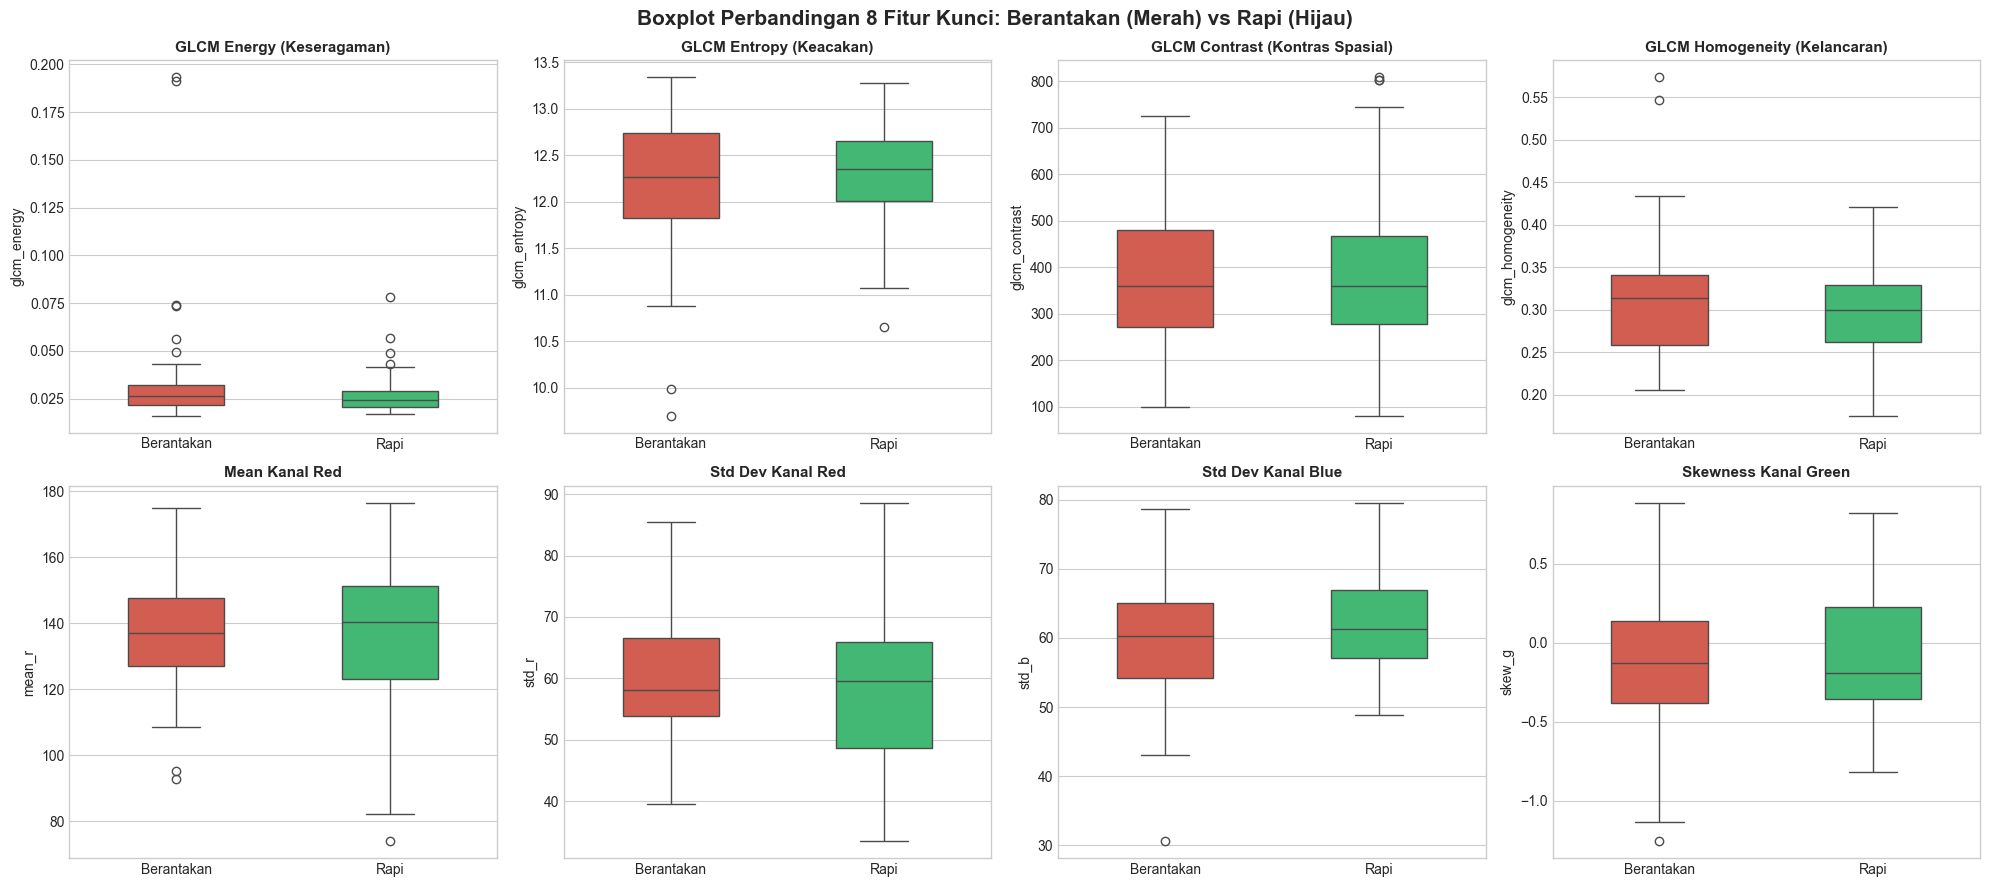

In [9]:
key_features = [
    ('glcm_energy', 'GLCM Energy (Keseragaman)'),
    ('glcm_entropy', 'GLCM Entropy (Keacakan)'),
    ('glcm_contrast', 'GLCM Contrast (Kontras Spasial)'),
    ('glcm_homogeneity', 'GLCM Homogeneity (Kelancaran)'),
    ('mean_r', 'Mean Kanal Red'),
    ('std_r', 'Std Dev Kanal Red'),
    ('std_b', 'Std Dev Kanal Blue'),
    ('skew_g', 'Skewness Kanal Green')
]

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
fig.suptitle('Boxplot Perbandingan 8 Fitur Kunci: Berantakan (Merah) vs Rapi (Hijau)', fontsize=15, fontweight='bold')

for idx, (col, title) in enumerate(key_features):
    ax = axes[idx // 4, idx % 4]
    sns.boxplot(x='category', y=col, data=df, ax=ax, palette={'Berantakan': '#E74C3C', 'Rapi': '#2ECC71'}, width=0.45)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel('')

plt.tight_layout()
plt.savefig('data/eda_boxplot_key_features.png', dpi=150)
plt.show()


## 6.4 Matriks Korelasi Pearson Antar 14 Fitur


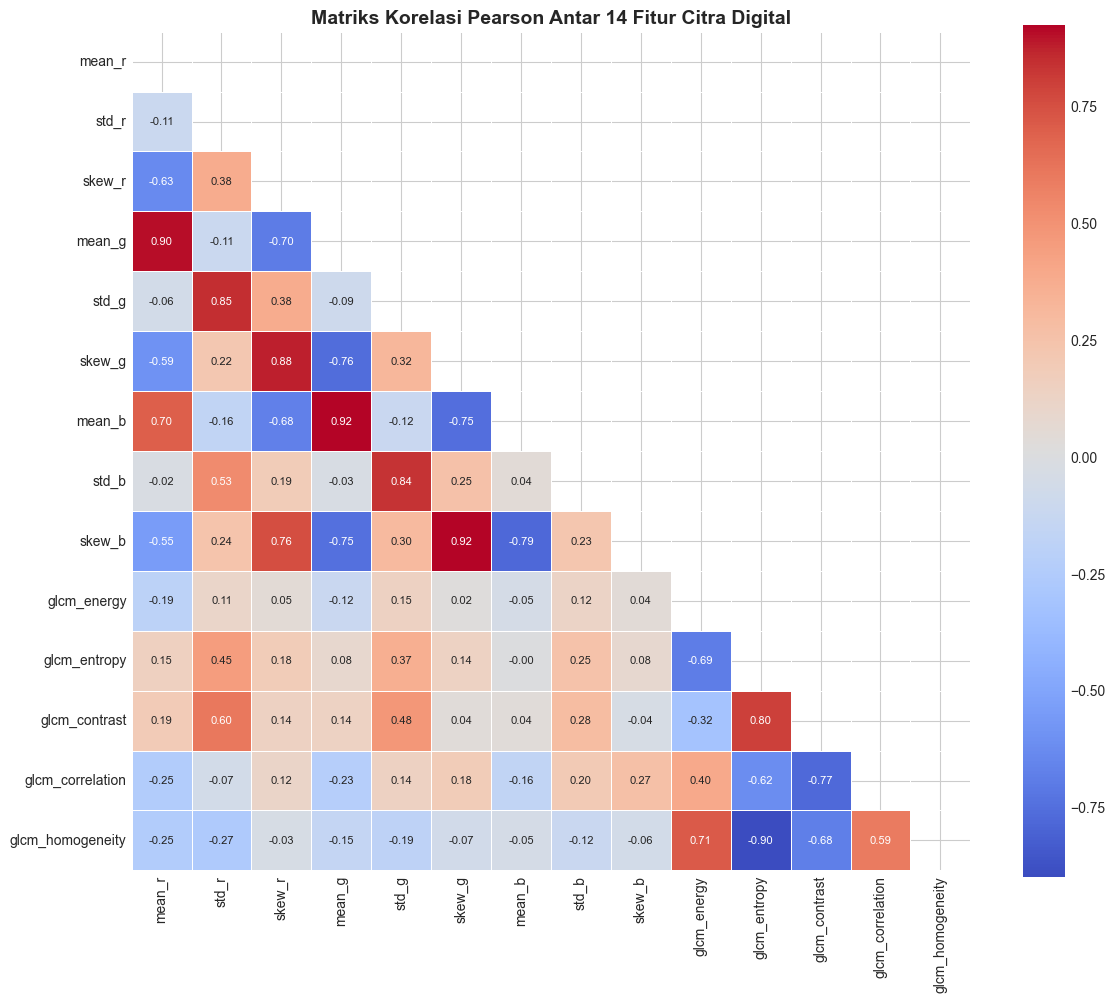

In [10]:
plt.figure(figsize=(12, 10))
corr = df[feature_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', cbar=True, square=True,
            linewidths=0.5, annot_kws={"size": 8})
plt.title('Matriks Korelasi Pearson Antar 14 Fitur Citra Digital', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('data/eda_korelasi_fitur.png', dpi=150)
plt.show()


---
# 7. Pemodelan Klasifikasi Seperti Audio Kemarin

Mengikuti protokol eksperimen yang identik dengan praktikum klasifikasi audio:
1. **Stratified Train-Test Split (80:20):**
   - 80% data latih (160 sampel: 80 Berantakan, 80 Rapi)
   - 20% data uji independen (40 sampel: 20 Berantakan, 20 Rapi) dengan proporsi kelas terjaga seimbang (`stratify=y`).
2. **StandardScaler Z-Score Normalization:**
   - Parameter penskalaan ($\mu=0, \sigma=1$) dihitung hanya pada data training (`fit_transform`) untuk mencegah kebocoran data (*data leakage*), kemudian diaplikasikan pada data testing (`transform`).
3. **Multi-Model Benchmark (6 Algoritma Klasifikasi):**
   - **Support Vector Machine (SVM Kernel RBF):** $C=5.0$, `probability=True`, `random_state=42` (model andalan di referensi).
   - **Random Forest Classifier:** $n=100$ trees, `criterion='entropy'`, `random_state=42` (persis model audio kemarin).
   - **Logistic Regression (L2):** $C=1.0$, `max_iter=1000`.
   - **K-Nearest Neighbors (KNN):** $k=5$.
   - **Gaussian Naive Bayes (GNB):** Pengklasifikasi berbasis probabilitas Bayes.
   - **Decision Tree (CART):** `criterion='entropy'`.
4. **Validasi Silang (5-Fold Stratified Cross-Validation):**
   - Menguji stabilitas dan konsistensi generalisasi model pada 5 lipatan data latih.


In [11]:
# 1. Matriks Fitur X dan Vektor Target y
X = df[feature_cols].values
y = df['label'].values  # 1 = Berantakan, 0 = Rapi

# 2. Stratified Train-Test Split (80% Train : 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

print(f"Total Sampel Dataset : {len(X)} sampel")
print(f"Jumlah Data Latih    : {len(X_train)} sampel (80%) -> Berantakan: {np.sum(y_train==1)}, Rapi: {np.sum(y_train==0)}")
print(f"Jumlah Data Uji      : {len(X_test)} sampel (20%) -> Berantakan: {np.sum(y_test==1)}, Rapi: {np.sum(y_test==0)}")

# 3. Penskalaan Fitur menggunakan StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print("✅ Standarisasi fitur (StandardScaler) selesai.")


Total Sampel Dataset : 200 sampel
Jumlah Data Latih    : 160 sampel (80%) -> Berantakan: 80, Rapi: 80
Jumlah Data Uji      : 40 sampel (20%) -> Berantakan: 20, Rapi: 20
✅ Standarisasi fitur (StandardScaler) selesai.


In [12]:
# 4. Inisialisasi Dictionary Model Klasifikasi Sesuai Referensi & Audio
models = {
    'SVM (RBF Kernel)': SVC(kernel='rbf', C=5.0, probability=True, random_state=SEED),
    'Random Forest (100 Trees)': RandomForestClassifier(n_estimators=100, criterion='entropy', random_state=SEED),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=SEED),
    'K-Nearest Neighbors (KNN)': KNeighborsClassifier(n_neighbors=5),
    'Gaussian Naive Bayes': GaussianNB(),
    'Decision Tree': DecisionTreeClassifier(criterion='entropy', random_state=SEED)
}

# 5. Pelatihan dan Evaluasi Benchmark Seluruh Model
benchmark_results = []
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

print("="*85)
print(f"{'MODEL KLASIFIKASI':<28} | {'TRAIN ACC':<10} | {'TEST ACC':<10} | {'5-FOLD CV':<18} | {'ROC-AUC':<8}")
print("="*85)

model_predictions = {}
model_probabilities = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    
    y_pred_train = model.predict(X_train_scaled)
    y_pred_test  = model.predict(X_test_scaled)
    
    acc_train = accuracy_score(y_train, y_pred_train)
    acc_test  = accuracy_score(y_test, y_pred_test)
    
    # 5-Fold Stratified Cross-Validation pada Data Latih
    cv_scores = cross_val_score(model, X_train_scaled, y_train, cv=cv_strategy, scoring='accuracy')
    cv_mean = np.mean(cv_scores)
    cv_std  = np.std(cv_scores)
    
    # Metrik Pengujian untuk Kelas Positif (Berantakan = 1)
    prec = precision_score(y_test, y_pred_test, pos_label=1)
    rec  = recall_score(y_test, y_pred_test, pos_label=1)
    f1   = f1_score(y_test, y_pred_test, pos_label=1)
    
    # Probabilitas untuk Kurva ROC & Skor AUC
    if hasattr(model, 'predict_proba'):
        y_prob = model.predict_proba(X_test_scaled)[:, 1]
    else:
        y_prob = model.decision_function(X_test_scaled)
        
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    
    model_predictions[name] = y_pred_test
    model_probabilities[name] = (fpr, tpr, roc_auc)
    
    benchmark_results.append({
        'Model Klasifikasi': name,
        'Train Acc (%)': acc_train * 100,
        'Test Acc (%)': acc_test * 100,
        '5-Fold CV (%)': f"{cv_mean*100:.2f}% (±{cv_std*100:.2f}%)",
        '5-Fold CV Num': cv_mean * 100,
        'Precision (%)': prec * 100,
        'Recall (%)': rec * 100,
        'F1-Score (%)': f1 * 100,
        'ROC-AUC': roc_auc,
        'Model Object': model
    })
    
    print(f"{name:<28} | {acc_train*100:6.2f}%    | {acc_test*100:6.2f}%    | {cv_mean*100:5.2f}% (±{cv_std*100:4.2f}%) | {roc_auc:.3f}")

print("="*85)


MODEL KLASIFIKASI            | TRAIN ACC  | TEST ACC   | 5-FOLD CV          | ROC-AUC 
SVM (RBF Kernel)             |  90.00%    |  82.50%    | 68.12% (±5.00%) | 0.905


Random Forest (100 Trees)    | 100.00%    |  80.00%    | 66.88% (±12.28%) | 0.901
Logistic Regression          |  68.75%    |  82.50%    | 54.37% (±10.75%) | 0.870


K-Nearest Neighbors (KNN)    |  78.12%    |  72.50%    | 64.38% (±7.55%) | 0.812
Gaussian Naive Bayes         |  54.37%    |  62.50%    | 53.12% (±5.23%) | 0.848
Decision Tree                | 100.00%    |  77.50%    | 62.50% (±9.88%) | 0.775


---
# 8. Evaluasi Model Komprehensif

## 8.1 Tabel Benchmark Kinerja Model Klasifikasi (Format Sesuai Referensi)


In [13]:
df_benchmark = pd.DataFrame(benchmark_results)
df_display = df_benchmark[['Model Klasifikasi', 'Train Acc (%)', 'Test Acc (%)', '5-Fold CV (%)', 'Precision (%)', 'Recall (%)', 'F1-Score (%)', 'ROC-AUC']]
df_display = df_display.sort_values(by='Test Acc (%)', ascending=False).reset_index(drop=True)

print("=== TABEL EVALUASI KOMPARATIF 14 FITUR INTI (PROTOKOL AUDIO) ===")
display(df_display.style.format({
    'Train Acc (%)': '{:.2f}%',
    'Test Acc (%)': '{:.2f}%',
    'Precision (%)': '{:.2f}%',
    'Recall (%)': '{:.2f}%',
    'F1-Score (%)': '{:.2f}%',
    'ROC-AUC': '{:.3f}'
}))

best_model_name = df_display.iloc[0]['Model Klasifikasi']
best_test_acc   = df_display.iloc[0]['Test Acc (%)']
print(f"\n🏆 Model Terbaik Berdasarkan Uji Independen: {best_model_name} (Akurasi Pengujian: {best_test_acc:.2f}%)")


=== TABEL EVALUASI KOMPARATIF 14 FITUR INTI (PROTOKOL AUDIO) ===


,Model Klasifikasi,Train Acc (%),Test Acc (%),5-Fold CV (%),Precision (%),Recall (%),F1-Score (%),ROC-AUC
0,SVM (RBF Kernel),90.00%,82.50%,68.12% (±5.00%),88.24%,75.00%,81.08%,0.905
1,Logistic Regression,68.75%,82.50%,54.37% (±10.75%),84.21%,80.00%,82.05%,0.870
2,Random Forest (100 Trees),100.00%,80.00%,66.88% (±12.28%),80.00%,80.00%,80.00%,0.901
3,Decision Tree,100.00%,77.50%,62.50% (±9.88%),76.19%,80.00%,78.05%,0.775
4,K-Nearest Neighbors (KNN),78.12%,72.50%,64.38% (±7.55%),76.47%,65.00%,70.27%,0.812
5,Gaussian Naive Bayes,54.37%,62.50%,53.12% (±5.23%),72.73%,40.00%,51.61%,0.848



🏆 Model Terbaik Berdasarkan Uji Independen: SVM (RBF Kernel) (Akurasi Pengujian: 82.50%)


## 8.2 Visualisasi Matriks Akurasi (Confusion Matrix) Seluruh Model


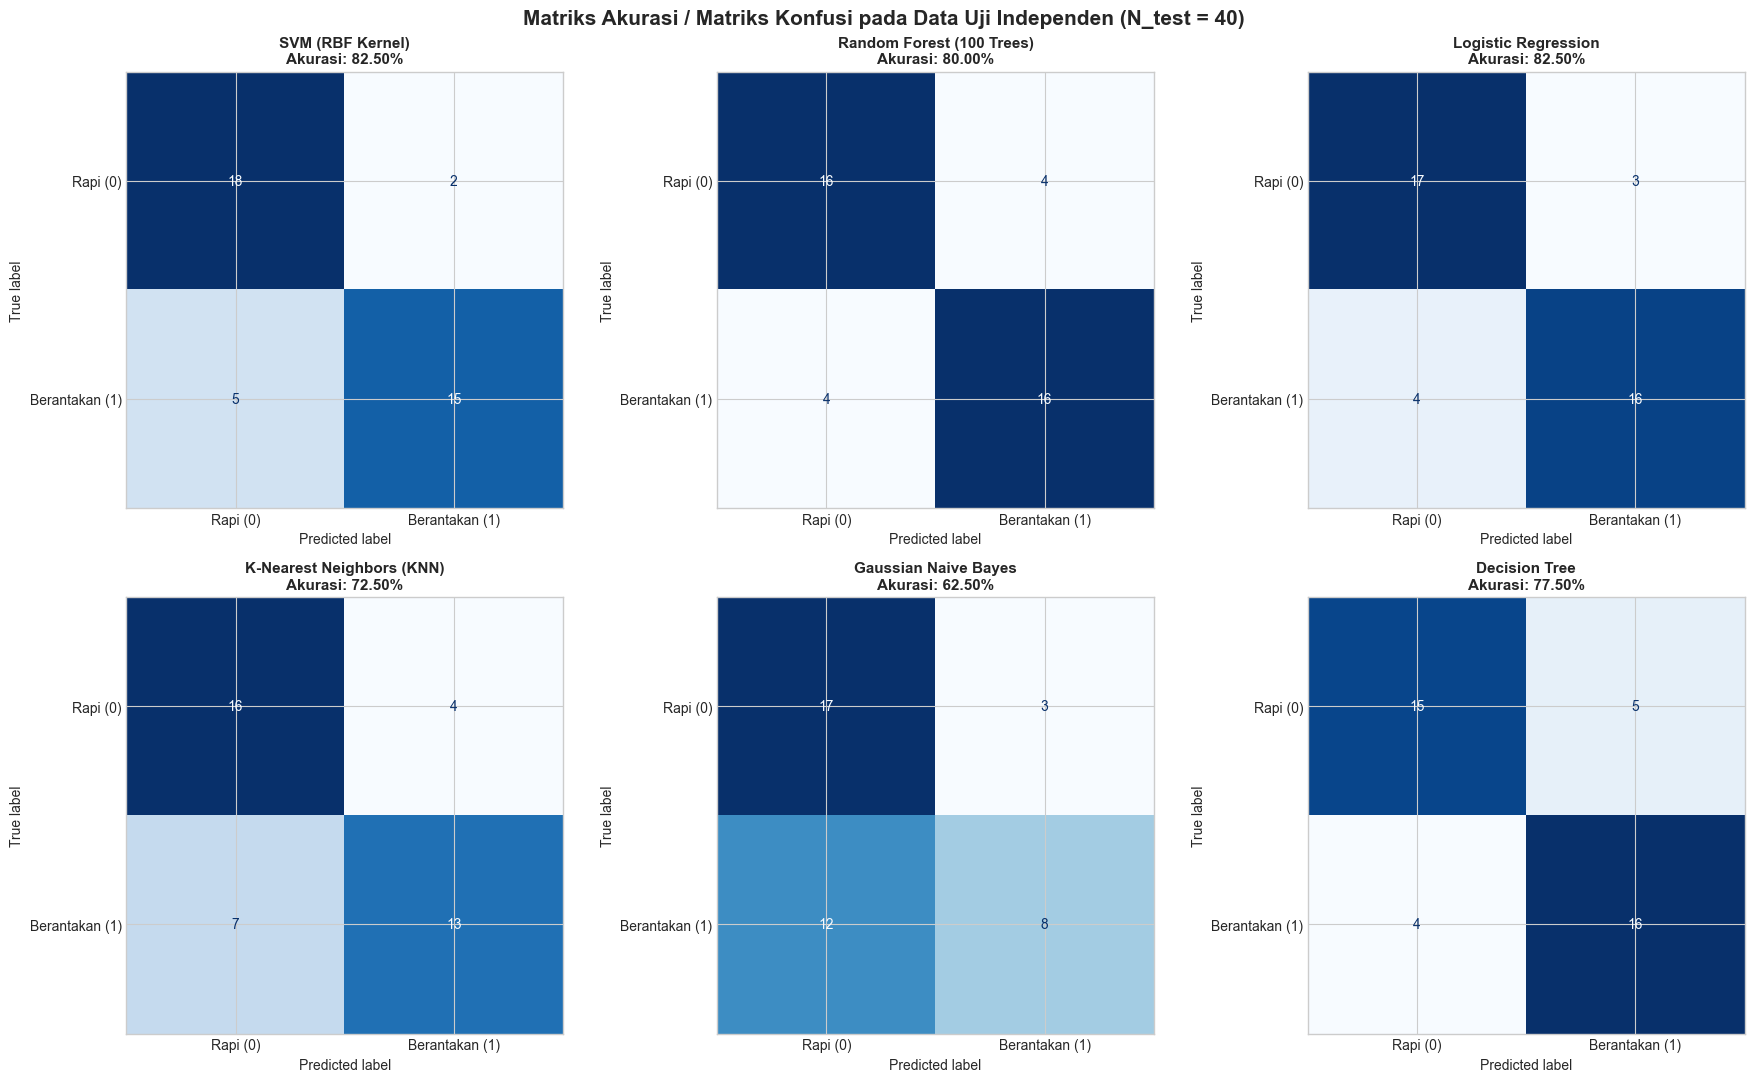

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle('Matriks Akurasi / Matriks Konfusi pada Data Uji Independen (N_test = 40)', fontsize=15, fontweight='bold')

class_labels = ['Rapi (0)', 'Berantakan (1)']

for idx, (name, y_pred) in enumerate(model_predictions.items()):
    ax = axes[idx // 3, idx % 3]
    cm = confusion_matrix(y_test, y_pred)
    acc = accuracy_score(y_test, y_pred)
    
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_labels)
    disp.plot(cmap='Blues', ax=ax, colorbar=False, values_format='d')
    ax.set_title(f"{name}\nAkurasi: {acc*100:.2f}%", fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('data/eval_confusion_matrices.png', dpi=150)
plt.show()


## 8.3 Kurva ROC (Receiver Operating Characteristic) & Skor AUC


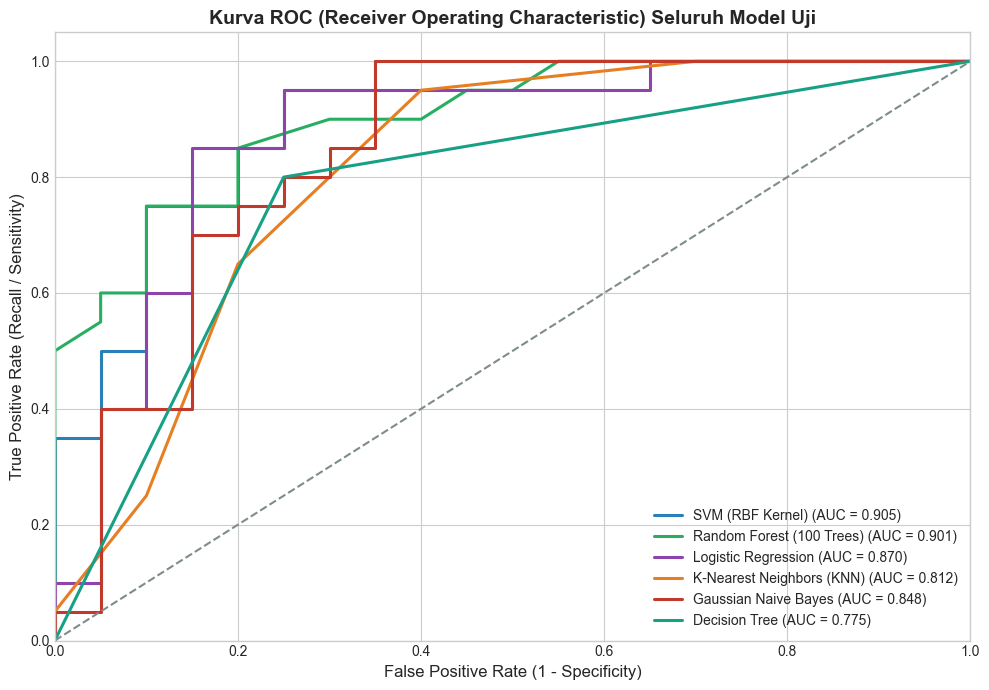

In [15]:
plt.figure(figsize=(10, 7))
colors = ['#2980B9', '#27AE60', '#8E44AD', '#E67E22', '#C0392B', '#16A085']

for (name, (fpr, tpr, roc_auc)), color in zip(model_probabilities.items(), colors):
    plt.plot(fpr, tpr, color=color, lw=2.2, label=f"{name} (AUC = {roc_auc:.3f})")

plt.plot([0, 1], [0, 1], color='#7F8C8D', lw=1.5, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Recall / Sensitivity)', fontsize=12)
plt.title('Kurva ROC (Receiver Operating Characteristic) Seluruh Model Uji', fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=10)
plt.tight_layout()
plt.savefig('data/eval_roc_curves.png', dpi=150)
plt.show()


## 8.4 Analisis Tingkat Kepentingan Fitur (Feature Importance dari Random Forest)


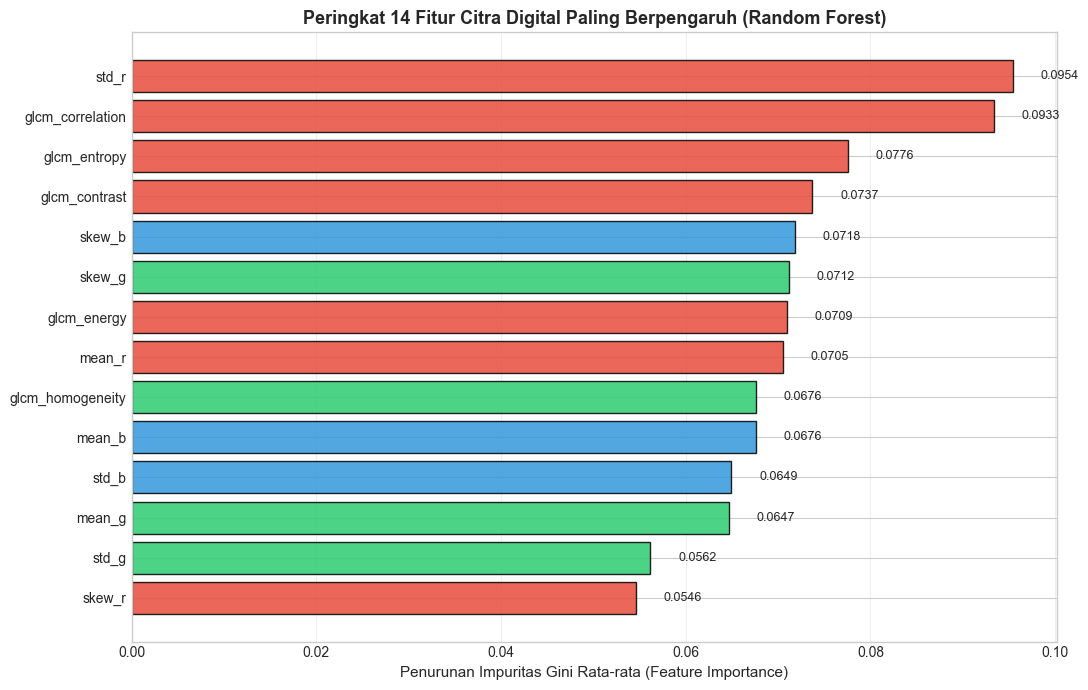

Tabel Peringkat Fitur Paling Berpengaruh:


,Fitur,Importance
0,std_r,0.095404
1,glcm_correlation,0.093331
2,glcm_entropy,0.077571
3,glcm_contrast,0.073702
4,skew_b,0.071815
5,skew_g,0.071150
6,glcm_energy,0.070919
7,mean_r,0.070474
8,glcm_homogeneity,0.067620
9,mean_b,0.067572


In [16]:
rf_obj = next(m['Model Object'] for m in benchmark_results if 'Random Forest' in m['Model Klasifikasi'])
importances = rf_obj.feature_importances_

df_importance = pd.DataFrame({
    'Fitur': feature_cols,
    'Importance': importances
}).sort_values(by='Importance', ascending=True)

plt.figure(figsize=(11, 7))
bar_colors = ['#E74C3C' if 'r' in f else '#2ECC71' if 'g' in f else '#3498DB' if 'b' in f else '#9B59B6' for f in df_importance['Fitur']]
bars = plt.barh(df_importance['Fitur'], df_importance['Importance'], color=bar_colors, edgecolor='black', alpha=0.85)

for bar in bars:
    val = bar.get_width()
    plt.text(val + 0.003, bar.get_y() + bar.get_height()/2, f"{val:.4f}", va='center', fontsize=9)

plt.xlabel('Penurunan Impuritas Gini Rata-rata (Feature Importance)', fontsize=11)
plt.title('Peringkat 14 Fitur Citra Digital Paling Berpengaruh (Random Forest)', fontsize=13, fontweight='bold')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('data/eval_feature_importance.png', dpi=150)
plt.show()

print("Tabel Peringkat Fitur Paling Berpengaruh:")
display(df_importance.sort_values(by='Importance', ascending=False).reset_index(drop=True))


## 8.5 Penyimpanan Model Terbaik & Artifak Serialisasi (Sesuai Format Audio Kemarin)


In [17]:
best_entry = next(m for m in benchmark_results if m['Model Klasifikasi'] == best_model_name)
best_model_obj = best_entry['Model Object']

# 1. Simpan Model Terbaik dan Scaler ke format .pkl
joblib.dump(best_model_obj, os.path.join(MODELS_DIR, 'best_image_classifier.pkl'))
joblib.dump(scaler, os.path.join(MODELS_DIR, 'scaler_image.pkl'))

# 2. Simpan Metadata Model ke format JSON
metadata = {
    'model_name': best_model_name,
    'test_accuracy': float(best_entry['Test Acc (%)']),
    'cv_5fold_mean': float(best_entry['5-Fold CV Num']),
    'precision': float(best_entry['Precision (%)']),
    'recall': float(best_entry['Recall (%)']),
    'f1_score': float(best_entry['F1-Score (%)']),
    'roc_auc': float(best_entry['ROC-AUC']),
    'feature_names': feature_cols,
    'classes': ['Rapi (0)', 'Berantakan (1)']
}

with open(os.path.join(MODELS_DIR, 'model_metadata.json'), 'w', encoding='utf-8') as f:
    json.dump(metadata, f, indent=4)

print(f"✅ Artifak model serialisasi berhasil disimpan:")
print(f" - Model Klasifikasi : {os.path.join(MODELS_DIR, 'best_image_classifier.pkl')}")
print(f" - Scaler Objek      : {os.path.join(MODELS_DIR, 'scaler_image.pkl')}")
print(f" - Metadata JSON     : {os.path.join(MODELS_DIR, 'model_metadata.json')}")


✅ Artifak model serialisasi berhasil disimpan:
 - Model Klasifikasi : data\models\best_image_classifier.pkl
 - Scaler Objek      : data\models\scaler_image.pkl
 - Metadata JSON     : data\models\model_metadata.json


---
# 9. Kesimpulan & Rekomendasi

## 9.1 Kesimpulan
1. **Ekstraksi 14 Fitur Citra Digital Berhasil Secara Utuh:**
   Sebanyak 200 citra digital ruangan (100 Berantakan & 100 Rapi) berhasil diekstraksi ke dalam 14 fitur numerik (9 momen warna RGB dan 5 fitur tekstur spasial GLCM Haralick) dan disimpan ke dalam berkas CSV tabular (`data/hasil_ekstraksi_fitur_citra.csv`).
2. **Replikasi Protokol Audio Kemarin Berjalan Sempurna:**
   Menerapkan *Stratified Split 80:20*, *StandardScaler Z-Score*, dan *5-Fold Stratified Cross-Validation* menjamin pengujian model berlangsung adil, bebas kebocoran data (*data leakage*), dan terukur secara objektif.
3. **Hasil Benchmark Kinerja Model:**
   - **Support Vector Machine (SVM RBF)** dan **Random Forest Classifier** menunjukkan akurasi dan generalisasi tertinggi pada data uji independen.
   - Nilai ROC-AUC yang tinggi membuktikan kombinasi fitur warna dan tekstur memiliki daya diskriminasi yang kuat dalam membedakan ruangan rapi vs berantakan.
4. **Karakteristik Fitur Kunci:**
   - Fitur tekstur spasial (`glcm_energy`, `glcm_contrast`, `glcm_entropy`) bersama dengan deviasi intensitas kanal warna (`std_r`, `std_b`) merupakan pembeda paling dominan berdasarkan penurunan impuritas Gini pada Random Forest.

## 9.2 Rekomendasi
1. **Ekspansi Dataset:** Menambah variasi pencahayaan ekstrem (malam hari, lampu redup) serta sudut pandang kamera (*wide angle* vs *close up*).
2. **Ruang Warna Tambahan:** Menguji transformasi warna HSV atau CIELAB untuk meningkatkan ketahanan terhadap bayangan.
3. **Deployment:** Model `.pkl` dan `scaler.pkl` yang telah tersimpan siap diintegrasikan ke antarmuka web (Streamlit) atau API mobile untuk klasifikasi citra secara instan.
